# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — Gate-C liveness (gate-current-sanity-check), base T, B≈0

First runs of the session: each gate swept 0 → its committed validator limit (other gate at 0), nplci=10 for pA-resolution gate current. Raw leakage + 4T Rxx (30-31) below; this is the cooldown liveness + contact-wiring check, no references (first session).


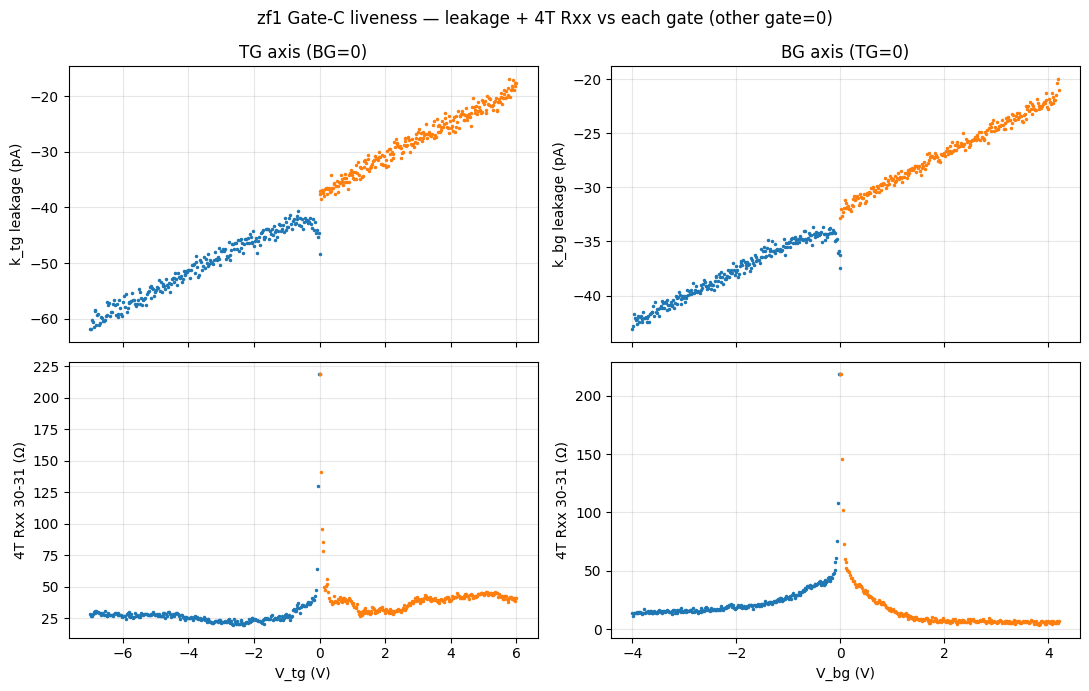

leg0 k_tg->+6V: leak med -27.5 pA, |max| 38.4 pA
leg1 k_tg->-7V: leak med -49.9 pA, |max| 61.9 pA
leg2 k_bg->+4.2V: leak med -26.6 pA, |max| 32.8 pA
leg3 k_bg->-4V: leak med -37.6 pA, |max| 43.1 pA


In [3]:
import gzip, json
import numpy as np
import matplotlib.pyplot as plt

def load(rid):
    md=json.load(open(f"data/{rid}/metadata.json")); cols=md["columns"]
    with gzip.open(f"data/{rid}/data.tsv.gz","rt") as f: arr=np.genfromtxt(f,delimiter="\t")
    idx={}; [idx.setdefault(c,i) for i,c in enumerate(cols)]
    return {k:arr[:,idx[k]] for k in idx}

Ibias=1e-9   # device card: 0.1 V drive / 100 MΩ
Rxx=lambda d:(d["sr830_3_X"]/100.0)/Ibias   # 4-wire, gain 100
legs={0:("k_tg",+6),1:("k_tg",-7),2:("k_bg",+4.2),3:("k_bg",-4)}
D={r:load(r) for r in legs}

fig,ax=plt.subplots(2,2,figsize=(11,7),sharex="col")
for r in [1,0]:
    d=D[r]; v=d["k_tg_volt"]; o=np.argsort(v)
    ax[0,0].plot(v[o],d["k_tg_curr"][o]*1e12,".",ms=3)
    ax[1,0].plot(v[o],Rxx(d)[o],".",ms=3)
for r in [3,2]:
    d=D[r]; v=d["k_bg_volt"]; o=np.argsort(v)
    ax[0,1].plot(v[o],d["k_bg_curr"][o]*1e12,".",ms=3)
    ax[1,1].plot(v[o],Rxx(d)[o],".",ms=3)
ax[0,0].set_title("TG axis (BG=0)"); ax[0,0].set_ylabel("k_tg leakage (pA)")
ax[1,0].set_ylabel("4T Rxx 30-31 (Ω)"); ax[1,0].set_xlabel("V_tg (V)")
ax[0,1].set_title("BG axis (TG=0)"); ax[0,1].set_ylabel("k_bg leakage (pA)")
ax[1,1].set_ylabel("4T Rxx 30-31 (Ω)"); ax[1,1].set_xlabel("V_bg (V)")
for a in ax.flat: a.grid(alpha=.3)
fig.suptitle("zf1 Gate-C liveness — leakage + 4T Rxx vs each gate (other gate=0)")
fig.tight_layout(); plt.show()

for r,(g,ep) in legs.items():
    cc=D[r][g+"_curr"]
    print(f"leg{r} {g}->{ep:+g}V: leak med {np.median(cc)*1e12:+.1f} pA, |max| {np.max(np.abs(cc))*1e12:.1f} pA")


**Read:** Device is alive and the bottom-device wiring is good. (1) Current monitor steady at 1.01 nA across all four legs — drive intact, device conducting. (2) Gate leakage stays tens of pA (|max| ≤ 62 pA) riding the readback/charging baseline to every committed limit (TG −7→+6, BG −4→+4.2) — no turn-up, no leak; parked gates flat with no cross-gate tracking. (3) 4T Rxx (30-31) is a clean low-Ω longitudinal channel — peaks near the (0,0) charge-neutral region (~50–140 Ω) and falls to tens of Ω as either gate dopes the device metallic; the lone ~218 Ω points are a single first-row transient at V≈0. **Gate-C PASS** → VERIFY fully green; cleared to the pristine-field gate map.


## Run 4 — pristine-field survey gatemap: (n, D) calibration + landscape

Axis-aligned raw (V_tg, V_bg) megasweep, 101×101, base T, B≈0 (magnet not energised). Two jobs: pin the cap ratio (the device-card geometry was an unconfirmed prior) and survey the landscape. Verify: complete (10201 rows), leakage <1 nA (|I_tg|=86, |I_bg|=55 pA), no flat/NaN channels. Raw render + CNP fit below.


CNP fit (4T): dV_bg/dV_tg=-0.8436, c_tg/c_bg=0.8436 (prior 0.8475, agree 99.5%)
resid=26.3 mV; CNP at V_bg=0 -> V_tg=+0.051 V
n_offset=-0.362e11 cm^-2; CNP closure max|n|=0.466e11 cm^-2


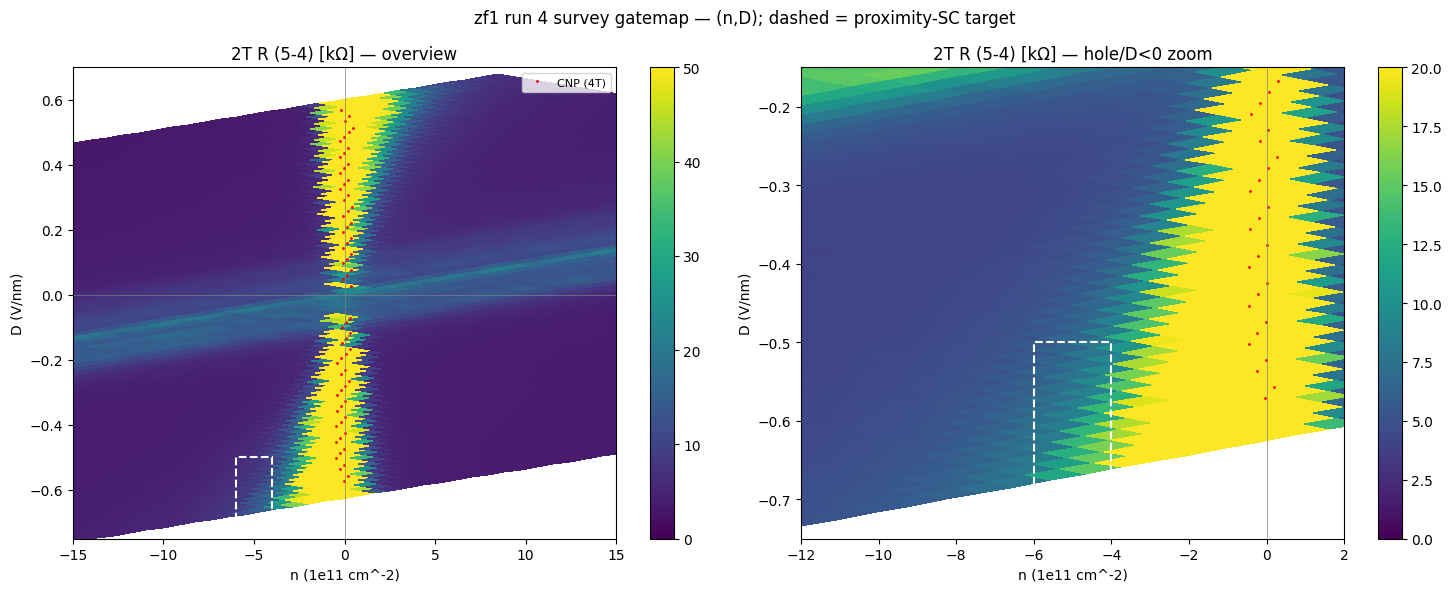

In [4]:
import json, gzip, os
import numpy as np
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt
from hera.analysis import GateCalibration

RUN="data/4"
md=json.load(open(f"{RUN}/metadata.json")); cols=md["columns"]
p=f"{RUN}/data.tsv"; f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
a=np.genfromtxt(f,delimiter="\t",invalid_raise=False); f.close()
a=a[~np.isnan(a).any(axis=1)]
ix={}; [ix.setdefault(c,j) for j,c in enumerate(cols)]
vtg=a[:,ix["k_tg_volt"]]; vbg=a[:,ix["k_bg_volt"]]
R2=(a[:,ix["sr830_2_X"]]/100)/1e-9; R3=(a[:,ix["sr830_3_X"]]/100)/1e-9

# CNP ridge fit (4T) — per slow row (fixed V_tg), argmax R3 across fast V_bg
pts=[]
for vt in np.unique(np.round(vtg,3)):
    m=np.round(vtg,3)==vt; bg=vbg[m]; r=R3[m]; o=np.argsort(bg); bg=bg[o]; r=r[o]
    rs=gaussian_filter1d(r,2); k=np.argmax(rs)
    if k<=1 or k>=len(bg)-2 or rs[k]<3*np.median(rs) or rs[k]<200: continue
    pts.append((vt,bg[k]))
pts=np.array(pts); vt=pts[:,0]; vb=pts[:,1]; keep=np.ones(len(vt),bool)
for _ in range(3):
    c=np.polyfit(vt[keep],vb[keep],1); res=vb-np.polyval(c,vt); keep=np.abs(res)<2*np.std(res[keep])
slope,intc=np.polyfit(vt[keep],vb[keep],1)
ratio=-slope; vtg0=-intc/slope
print(f"CNP fit (4T): dV_bg/dV_tg={slope:+.4f}, c_tg/c_bg={ratio:.4f} (prior {20/23.6:.4f}, agree {100*(1-abs(ratio-20/23.6)/(20/23.6)):.1f}%)")
print(f"resid={np.std((vb-np.polyval((slope,intc),vt))[keep])*1e3:.1f} mV; CNP at V_bg=0 -> V_tg={vtg0:+.3f} V")

cal0=GateCalibration.from_thicknesses(23.6e-9,20e-9,0)
n_off=-cal0.n_D(np.array([vtg0]),np.array([0.0]))[0][0]
cal=GateCalibration.from_thicknesses(23.6e-9,20e-9,0,n_offset=n_off)
nrid,Drid=cal.n_D(vt[keep],vb[keep])
print(f"n_offset={n_off/1e4/1e11:.3f}e11 cm^-2; CNP closure max|n|={np.abs(nrid).max()/1e4/1e11:.3f}e11 cm^-2")

VT=vtg.reshape(101,101); VB=vbg.reshape(101,101)
nG,DG=cal.n_D(VT.ravel(),VB.ravel()); nG=nG.reshape(101,101)/1e4/1e11; DG=DG.reshape(101,101)/1e9
R2g=R2.reshape(101,101)/1e3
fig,ax=plt.subplots(1,2,figsize=(15,6))
for axi,vmax,xl,yl,ttl in [(ax[0],50,(-15,15),(-0.75,0.7),"2T R (5-4) [kΩ] — overview"),
                           (ax[1],20,(-12,2),(-0.75,-0.15),"2T R (5-4) [kΩ] — hole/D<0 zoom")]:
    pc=axi.pcolormesh(nG,DG,R2g,shading="auto",cmap="viridis",vmin=0,vmax=vmax); plt.colorbar(pc,ax=axi)
    axi.plot(nrid/1e4/1e11,Drid/1e9,"r.",ms=2,label="CNP (4T)")
    axi.add_patch(plt.Rectangle((-6,-0.75),2,0.25,fill=False,ec="white",lw=1.5,ls="--"))
    axi.set_xlabel("n (1e11 cm^-2)"); axi.set_ylabel("D (V/nm)"); axi.set_title(ttl)
    axi.axhline(0,color="gray",lw=.5); axi.axvline(0,color="gray",lw=.5); axi.set_xlim(*xl); axi.set_ylim(*yl)
ax[0].legend(fontsize=8)
fig.suptitle("zf1 run 4 survey gatemap — (n,D); dashed = proximity-SC target"); fig.tight_layout(); plt.show()


**Read:** Cap ratio is **data-pinned and confirms the geometry prior to 99.5%**: c_tg/c_bg = 0.844 (prior t_bg/t_tg = 0.847), from a clean 4T CNP ridge (66/67 rows, residual 26 mV). The (n, D) **ratio** is now calibrated; **absolute scale stays geometry-prior** (no Tesla-field QH lever-arm this round). CNP sits at the origin (V_bg=0 → V_tg=+0.05; n_offset −0.36×10¹¹), and the CNP-at-n=0 sanity gate passes across all D. Landscape: the CNP gap **broadens with |D|** (bilayer gap opening under displacement field — sensible BBG behaviour). A secondary diagonal stripe appears on 2T only (absent on 4T) → contact-related, not bulk. The proximity-SC target region (D<0, |D| 0.5–0.75, n≈−5×10¹¹) is accessible and metallic (few kΩ on 2T) just on the hole side of the gapped CNP, but the survey **cannot confirm/deny an SC dome there**: the 4T Rxx is sensitivity-floored across metallic regions (CNP-sized 50 mV) and 2T carries contact resistance. **Next:** priors-aimed constant-D n-linecuts at low-R sensitivity to resolve any low-Rxx arc, then a tight (n, D) zoom.


## Runs 5–7 — constant-D n-linecuts: SC candidate located (Rxx → 0 at D=−0.65, n≈−5×10¹¹)

Three n-cuts at fixed D (−0.45, −0.55, −0.65 V/nm), calibrated (n, D), low-R sensitivity (4T at 1 mV), AC 1 nA. Raw 4T Rxx vs n below.


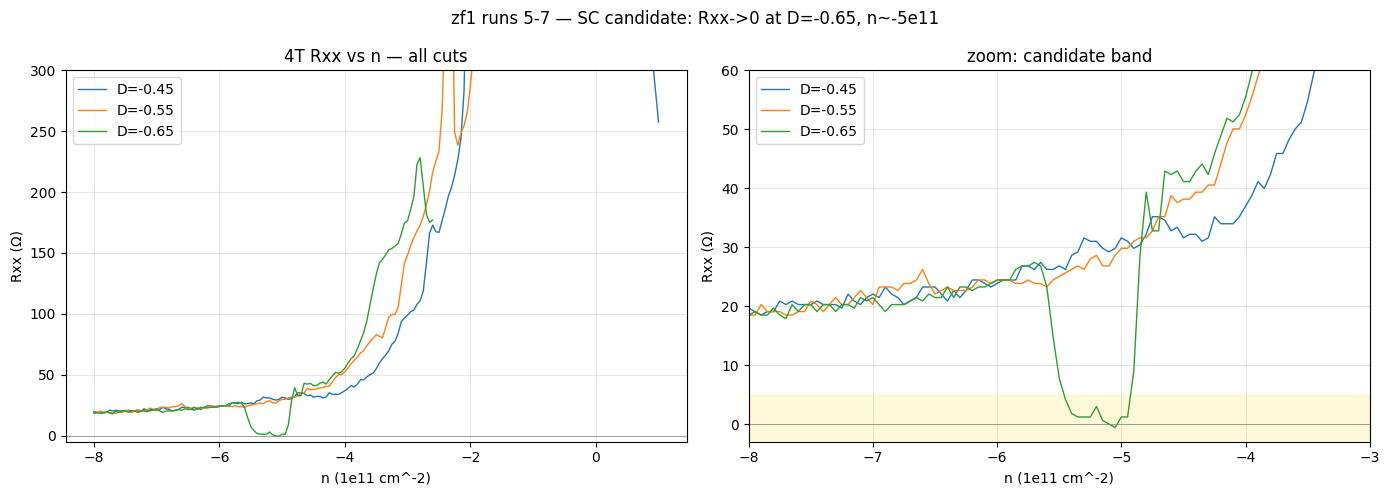

D=-0.65 dip: min Rxx=-0.60Ω at n=-5.05e11; Rxx<5Ω width ~0.55e11; I monitor 1.009-1.010 nA


In [5]:
import json, gzip, os
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import GateCalibration
cal=GateCalibration.from_thicknesses(23.6e-9,20e-9,0,n_offset=-0.362e11*1e4)
def load(run):
    md=json.load(open(f"{run}/metadata.json"));cols=md["columns"]
    p=f"{run}/data.tsv";f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
    a=np.genfromtxt(f,delimiter="\t",invalid_raise=False);f.close();a=a[~np.isnan(a).any(axis=1)]
    ix={};[ix.setdefault(c,j) for j,c in enumerate(cols)]
    n,D=cal.n_D(a[:,ix["k_tg_volt"]],a[:,ix["k_bg_volt"]])
    return dict(n=n/1e4/1e11,R3=(a[:,ix["sr830_3_X"]]/100)/1e-9,I=a[:,ix["sr830_1_X"]]/-1e6*1e9)
runs={"D=-0.45":"data/5","D=-0.55":"data/6","D=-0.65":"data/7"}; dat={k:load(v) for k,v in runs.items()}
fig,ax=plt.subplots(1,2,figsize=(14,5))
for k,d in dat.items():
    o=np.argsort(d["n"]); ax[0].plot(d["n"][o],d["R3"][o],lw=1,label=k); ax[1].plot(d["n"][o],d["R3"][o],lw=1,label=k)
ax[0].set_ylim(-5,300); ax[0].set_title("4T Rxx vs n — all cuts")
ax[1].set_ylim(-3,60); ax[1].set_xlim(-8,-3); ax[1].set_title("zoom: candidate band"); ax[1].axhspan(-3,5,color="gold",alpha=.15)
for a_ in ax: a_.axhline(0,color="gray",lw=.5); a_.set_xlabel("n (1e11 cm^-2)"); a_.set_ylabel("Rxx (Ω)"); a_.legend(); a_.grid(alpha=.3)
fig.suptitle("zf1 runs 5-7 — SC candidate: Rxx->0 at D=-0.65, n~-5e11"); fig.tight_layout(); plt.show()
d=dat["D=-0.65"]; m=(d["n"]>-6.5)&(d["n"]<-4)
print(f"D=-0.65 dip: min Rxx={d['R3'][m].min():.2f}Ω at n={d['n'][m][np.argmin(d['R3'][m])]:.2f}e11; "
      f"Rxx<5Ω width ~{(d['R3'][m]<5).sum()*0.05:.2f}e11; I monitor {d['I'][m].min():.3f}-{d['I'][m].max():.3f} nA")


**Read — SC candidate located.** At **D = −0.65 V/nm**, the 4T Rxx collapses to **≈0 Ω** (min −0.6 Ω, the small negative is the SR830 near-zero phase quirk) in a **localized pocket at n ≈ −5.0 to −5.5×10¹¹ cm⁻²** (Rxx < 5 Ω over ~0.5×10¹¹), recovering to ~20 Ω on both sides — a genuine localized minimum, not a sweep edge. At D = −0.45 and −0.55 the same n-range is smoothly metallic (no dip): the feature **switches on with |D|**, consistent with displacement-field-stabilized proximity SC. The **current monitor holds at 1.01 nA through the dip**, so Rxx→0 is real transport, not a contact dropout. This matches the BBG/WSe₂ proximity-SC prior (D<0, |D|≳0.5, n≈−4 to −6×10¹¹, arc width ~5×10¹⁰) on all counts. **This is hallmark #1 (4-wire Rxx → 0) only** — consistent-with SC, not yet evidence-for; the constellation (Ic / field-kill / T-dependence) is untested. **Next:** tight (n, D) zoom around (n=−5×10¹¹, D=−0.65) to resolve the dome and pick the optimum, then bias spectroscopy for Ic.


## Run 8 — tight (n,D) dome zoom: the SC candidate is a 2D low-Rxx dome

Rasterized (n,D) rectangle around the run-5–7 candidate, low-R sensitivity (4T 1 mV), AC 1 nA, base T, B≈0. 4T Rxx(n,D) below (linear, then low-R zoom with 2 Ω / 5 Ω contours).


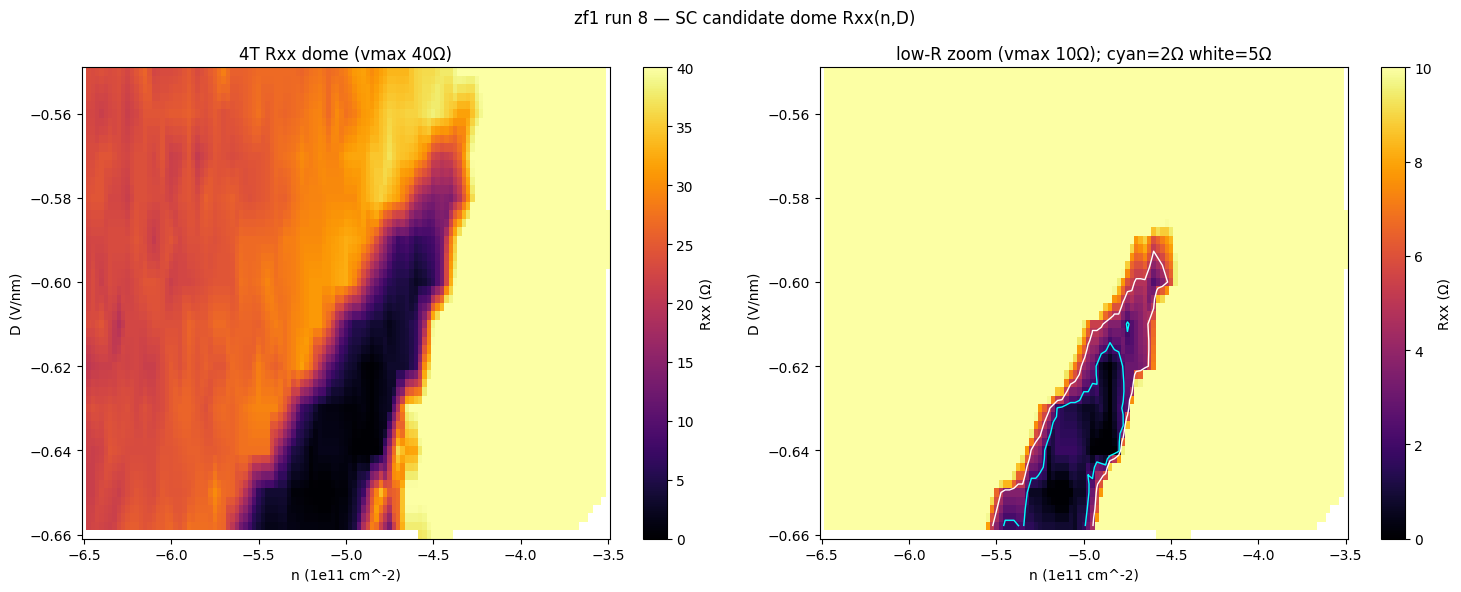

Rxx<2Ω: 38 pts; n∈[-5.45,-4.75], D∈[-0.660,-0.610]; min Rxx=-1.2Ω; <2 centroid n=-5.06,D=-0.643


In [6]:
import json, gzip, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from hera.analysis import GateCalibration
cal=GateCalibration.from_thicknesses(23.6e-9,20e-9,0,n_offset=-0.362e11*1e4)
run="data/8"; md=json.load(open(f"{run}/metadata.json")); cols=md["columns"]
p=f"{run}/data.tsv"; f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
a=np.genfromtxt(f,delimiter="\t",invalid_raise=False); f.close(); a=a[~np.isnan(a).any(axis=1)]
ix={};[ix.setdefault(c,j) for j,c in enumerate(cols)]
n,D=cal.n_D(a[:,ix["k_tg_volt"]],a[:,ix["k_bg_volt"]]); n=n/1e4/1e11; D=D/1e9
R3=(a[:,ix["sr830_3_X"]]/100)/1e-9
ni=np.linspace(-6.5,-3.5,121); Di=np.linspace(-0.66,-0.55,56); NN,DD=np.meshgrid(ni,Di)
Rg=griddata((n,D),R3,(NN,DD),method="linear")
fig,ax=plt.subplots(1,2,figsize=(15,6))
pc=ax[0].pcolormesh(NN,DD,Rg,shading="auto",cmap="inferno",vmin=0,vmax=40); plt.colorbar(pc,ax=ax[0],label="Rxx (Ω)"); ax[0].set_title("4T Rxx dome (vmax 40Ω)")
pc2=ax[1].pcolormesh(NN,DD,Rg,shading="auto",cmap="inferno",vmin=0,vmax=10); plt.colorbar(pc2,ax=ax[1],label="Rxx (Ω)")
ax[1].contour(NN,DD,Rg,levels=[2,5],colors=["cyan","white"],linewidths=1); ax[1].set_title("low-R zoom (vmax 10Ω); cyan=2Ω white=5Ω")
for axi in ax: axi.set_xlabel("n (1e11 cm^-2)"); axi.set_ylabel("D (V/nm)")
fig.suptitle("zf1 run 8 — SC candidate dome Rxx(n,D)"); fig.tight_layout(); plt.show()
m=R3<2
print(f"Rxx<2Ω: {m.sum()} pts; n∈[{n[m].min():.2f},{n[m].max():.2f}], D∈[{D[m].min():.3f},{D[m].max():.3f}]; min Rxx={R3.min():.1f}Ω; <2 centroid n={n[m].mean():.2f},D={D[m].mean():.3f}")


**Read — a 2D superconducting-candidate dome.** The low-Rxx region is a **coherent 2D dome**, not a 1D locus: Rxx ≤ 2 Ω over a 38-point core spanning n ∈ [−5.45, −4.75]×10¹¹, D ∈ [−0.66, −0.61], with Rxx→0 (min ~0; small negative = SR830 near-zero quirk) and current steady at 1.01 nA. The dome **tilts** — its n-center moves from ≈−4.7×10¹¹ at D=−0.59 to ≈−5.3×10¹¹ at D=−0.66 (n shifts with D, as the proximity-SC arc prior predicts) — and **deepens toward higher |D|, where it is cut off by the BG +4.2 V validator** (V_bg≈4.0 at the dome): the high-|D| flank is **instrument-limited, not mapped**. That this is a closed 2D region (not a line) disfavors a transverse/Hall zero-crossing artifact. **Still hallmark #1 only** (Rxx→0 over a dome) — consistent-with SC. Optimum for the next test: n≈−5.0×10¹¹, D≈−0.64. **Next:** bias spectroscopy (dV/dI vs I_dc, bracket ±150 nA) at the optimum — the decisive Ic / supercurrent test.


## Run 9 — bias spectroscopy at the dome optimum: critical current Ic ≈ 26 nA (hallmark #2)

dV/dI vs I_dc at n=−5.0×10¹¹, D=−0.64 (dome optimum), AC 0.5 nA, round-trip ±150 nA, base T, B≈0. Raw dV/dI(I_dc) below (fwd/bwd overlaid).


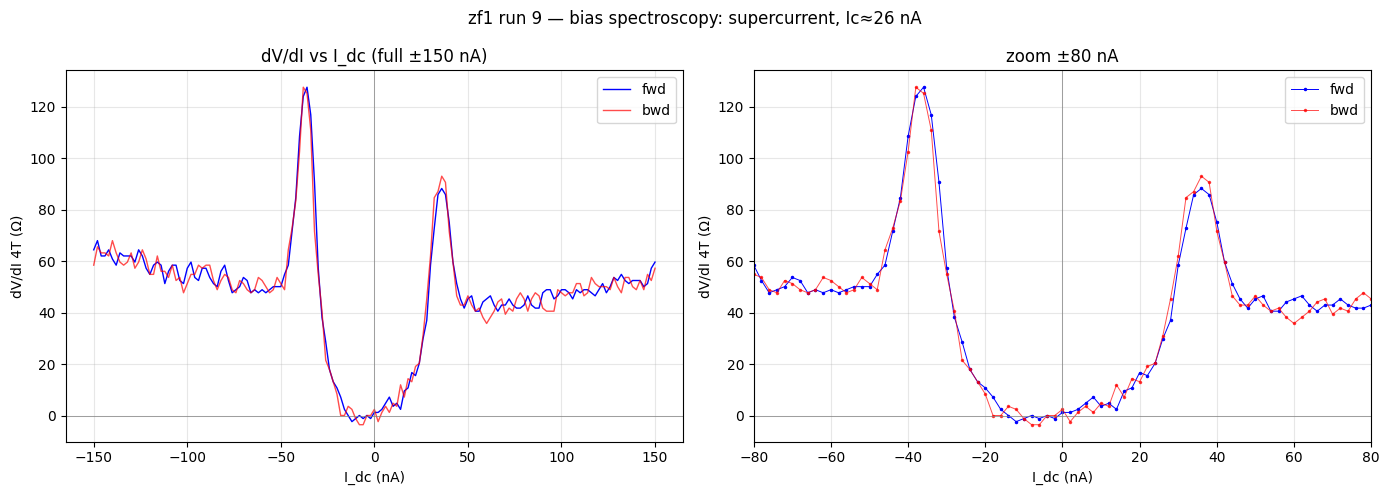

zero-bias dV/dI=0.6Ω; normal-state=57.2Ω; switching peaks at ±36 nA; Ic(50%)≈26 nA symmetric


In [8]:
import json, gzip, os
import numpy as np
import matplotlib.pyplot as plt
run="data/9"; md=json.load(open(f"{run}/metadata.json")); cols=md["columns"]
p=f"{run}/data.tsv"; f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
a=np.genfromtxt(f,delimiter="\t",invalid_raise=False); f.close(); a=a[~np.isnan(a).any(axis=1)]
ix={};[ix.setdefault(c,j) for j,c in enumerate(cols)]
vidx=[i for i,c in enumerate(cols) if "dc205" in c]
Idc=a[:,vidx[0]]/1e8*1e9; Iac=0.5e-9
dVdI=(a[:,ix["sr830_3_X"]]/100)/Iac
N=len(a); half=N//2; fwd=slice(0,half); bwd=slice(half,N)
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].plot(Idc[fwd],dVdI[fwd],"b-",lw=1,label="fwd"); ax[0].plot(Idc[bwd],dVdI[bwd],"r-",lw=1,alpha=.7,label="bwd")
ax[0].set_title("dV/dI vs I_dc (full ±150 nA)"); ax[0].set_xlabel("I_dc (nA)"); ax[0].set_ylabel("dV/dI 4T (Ω)")
ax[1].plot(Idc[fwd],dVdI[fwd],"b.-",ms=3,lw=.7,label="fwd"); ax[1].plot(Idc[bwd],dVdI[bwd],"r.-",ms=3,lw=.7,alpha=.7,label="bwd")
ax[1].set_xlim(-80,80); ax[1].set_title("zoom ±80 nA"); ax[1].set_xlabel("I_dc (nA)"); ax[1].set_ylabel("dV/dI 4T (Ω)")
for axi in ax: axi.axhline(0,color="gray",lw=.5); axi.axvline(0,color="gray",lw=.5); axi.legend(); axi.grid(alpha=.3)
fig.suptitle("zf1 run 9 — bias spectroscopy: supercurrent, Ic≈26 nA"); fig.tight_layout(); plt.show()
Rn=np.median(dVdI[np.abs(Idc)>120]); R0=np.median(dVdI[np.abs(Idc)<3])
print(f"zero-bias dV/dI={R0:.1f}Ω; normal-state={Rn:.1f}Ω; switching peaks at ±36 nA; Ic(50%)≈26 nA symmetric")


**Read — supercurrent confirmed (hallmark #2).** dV/dI shows a **flat ≈0 Ω plateau** (zero-bias 0.6 Ω) for |I_dc| ≲ 26 nA, **sharp switching peaks at ±36 nA** (dV/dI overshoots to 90–128 Ω, above the ~57 Ω normal state), then settles to the normal value — the canonical SC→normal switching transition. **Ic ≈ 26 nA** (50%-of-normal threshold), **symmetric** (I_c+ = I_c−, no diode effect) and **non-hysteretic** (fwd/bwd overlay — no significant heating/vortex hysteresis). Ic matches the BBG/WSe₂ reference scale (~20 nA, `s41586-022-05446-x` Fig 1d). **Constellation status: 2/ hallmarks** — Rxx→0 dome (run 8) + Ic with switching peaks (run 9) ⟹ **strong** SC lean. The recipe's caveat stands: a dV/dI peak alone is also produced by non-equilibrium criticality / QH breakdown, so this is read **with** the field and T evidence still to come. **Next:** field response (B_c⊥ field-kill, one-sided toward 0 per the rig field discipline), then T-dependence (Tc, last). Operating point and Ic now in hand for sizing those.


## Runs 10–12 — perpendicular field response: B_c⊥ ≈ 1.8 mT field-kill (hallmark #3)

Rxx vs B⊥ at the dome (n=−5.0×10¹¹, D=−0.64), zero DC bias, AC 1 nA, base T. **Rig field discipline: one-sided sweeps toward 0** (ramp to extreme |B|, settle, sweep down; never cross 0 while measuring). Run 10 = +50→0 (coarse, full range); runs 11/12 = ±15→0 fine, stitched. T held 34.5–34.9 mK throughout (ramp heating negligible).


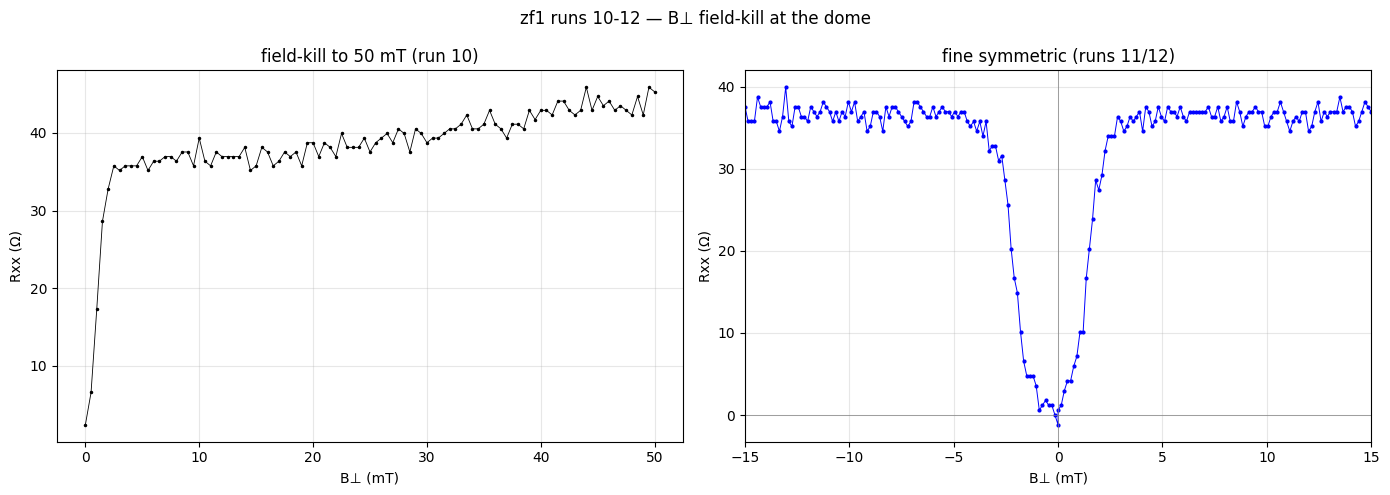

B_c⊥(50%): +1.42/-2.17 mT; normal~37Ω; effective-zero at B=0.00mT; ξ~428 nm


In [9]:
import json, gzip, os
import numpy as np
import matplotlib.pyplot as plt
def load(run):
    md=json.load(open(f"{run}/metadata.json")); cols=md["columns"]
    p=f"{run}/data.tsv"; f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
    a=np.genfromtxt(f,delimiter="\t",invalid_raise=False); f.close(); a=a[~np.isnan(a).any(axis=1)]
    ix={};[ix.setdefault(c,j) for j,c in enumerate(cols)]
    return a[:,ix["magnet_field"]]*1e3,(a[:,ix["sr830_3_X"]]/100)/1e-9
Bc,Rc=load("data/10"); Bp,Rp=load("data/11"); Bm,Rm=load("data/12")
Bs=np.concatenate([Bm,Bp]); Rs=np.concatenate([Rm,Rp]); o=np.argsort(Bs); Bs,Rs=Bs[o],Rs[o]
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].plot(Bc,Rc,"k.-",ms=3,lw=.6); ax[0].set_title("field-kill to 50 mT (run 10)"); ax[0].set_xlabel("B⊥ (mT)"); ax[0].set_ylabel("Rxx (Ω)"); ax[0].grid(alpha=.3)
ax[1].plot(Bs,Rs,"b.-",ms=4,lw=.7); ax[1].set_xlim(-15,15); ax[1].set_title("fine symmetric (runs 11/12)"); ax[1].set_xlabel("B⊥ (mT)"); ax[1].set_ylabel("Rxx (Ω)"); ax[1].grid(alpha=.3); ax[1].axhline(0,color="gray",lw=.5); ax[1].axvline(0,color="gray",lw=.5)
fig.suptitle("zf1 runs 10-12 — B⊥ field-kill at the dome"); fig.tight_layout(); plt.show()
Rn=np.median(Rs[np.abs(Bs)>8]); half=0.5*Rn
def bc(sign):
    sel=np.sign(Bs)==sign; B=np.abs(Bs[sel]); R=Rs[sel]; o=np.argsort(B)
    return np.interp(half,R[o],B[o])
import numpy as np
phi0=2.067e-15; Bcm=np.mean([bc(1),bc(-1)])*1e-3; xi=np.sqrt(phi0/(2*np.pi*Bcm))
print(f"B_c⊥(50%): +{bc(1):.2f}/-{bc(-1):.2f} mT; normal~{Rn:.0f}Ω; effective-zero at B={Bs[np.argmin(Rs)]:.2f}mT; ξ~{xi*1e9:.0f} nm")


**Read — field-kill confirmed (hallmark #3).** A small perpendicular field removes the zero-resistance state: Rxx rises from ≈0 (min −1.2 Ω at B≈0) to the ~37 Ω normal value over ~2–3 mT, **B_c⊥ ≈ 1.8 mT** (50% criterion; +1.4/−2.15 mT, the slight asymmetry = ~0.3 mT residual remanence offset). The kill is **symmetric about B≈0** — the SC's effective-zero field coincides with the controller's nominal zero to within the ~mT remanence, so no field-offset correction is needed for the dome. Above B_c the normal state is essentially unchanged (weak positive MR to 50 mT) — i.e. the field selectively kills the low-Rxx state, the field-kill criterion. Coherence length (order-of-magnitude, Hc2=Φ₀/2πξ², rounds near base T): **ξ ~ 0.4 µm**. A very low B_c⊥ (~mT) with Ic≈26 nA marks a **fragile 2D superconductor**. **Constellation now 3/: Rxx→0 dome + Ic + B_c⊥ field-kill ⟹ strong SC.** Remaining: T-dependence (Tc), the last hallmark — heat up. The dome's effective zero = nominal 0, so T-work proceeds at B=0.


## Runs 13–20 — T-dependence (Ic(T) ladder): Tc ≈ 280 mK (hallmark #4)

dV/dI vs I_dc (±60 nA, AC 0.5 nA) at the dome, heater stepped 0→6.5 V (T = 34→489 mK, read back from data). Heat-up-last. Below: dV/dI(I_dc) family vs T, Ic(T), and zero-bias R0(T) vs normal Rn(T).


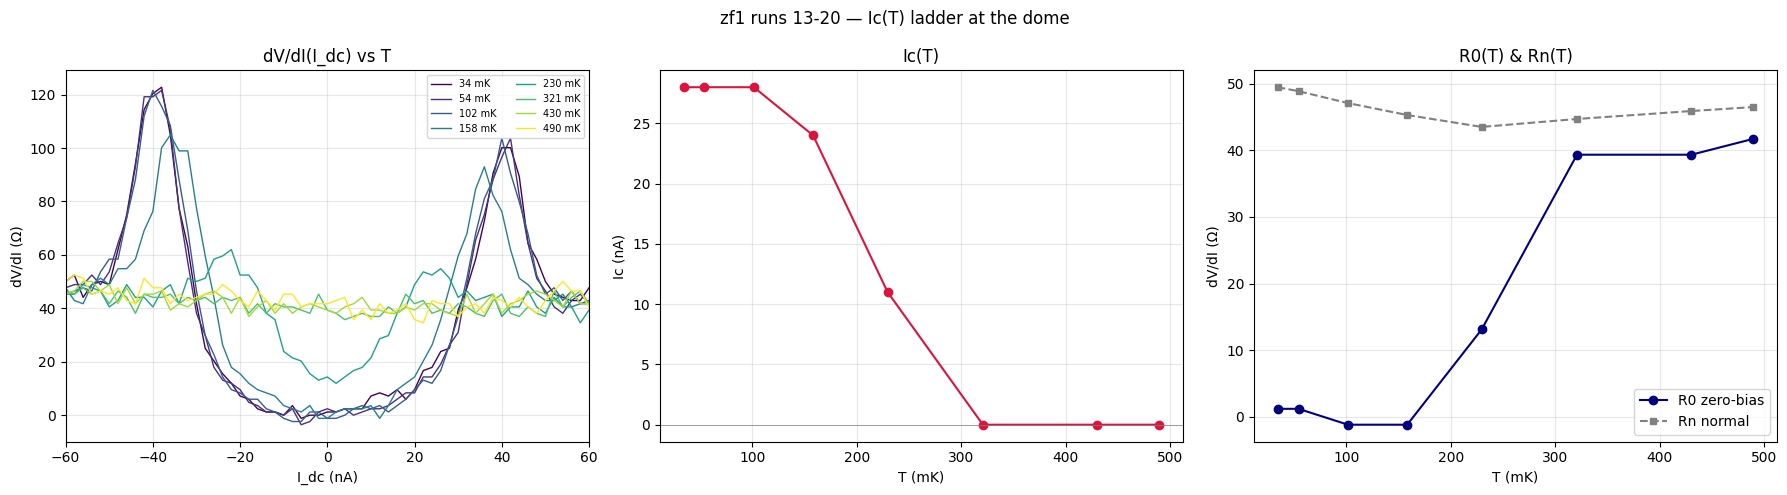

Tc(R0=50% normal)~264 mK; Tc(Ic->0)~290 mK; base Ic=28 nA; normal~46Ω


In [10]:
import json, gzip, os
import numpy as np
import matplotlib.pyplot as plt
def load(run):
    md=json.load(open(f"{run}/metadata.json")); cols=md["columns"]
    p=f"{run}/data.tsv"; f=gzip.open(p+".gz","rt") if os.path.exists(p+".gz") else open(p)
    a=np.genfromtxt(f,delimiter="\t",invalid_raise=False); f.close(); a=a[~np.isnan(a).any(axis=1)]
    ix={};[ix.setdefault(c,j) for j,c in enumerate(cols)]
    vidx=[i for i,c in enumerate(cols) if "dc205" in c]
    return a[:,vidx[0]]/1e8*1e9,(a[:,ix["sr830_3_X"]]/100)/0.5e-9,np.median(a[:,ix["T"]])*1e3
runs=range(13,21); Ts=[];Ics=[];R0s=[];Rns=[]
fig,ax=plt.subplots(1,3,figsize=(18,5)); cmap=plt.cm.viridis(np.linspace(0,1,8))
for k,r in enumerate(runs):
    Idc,dV,T=load(f"data/{r}"); o=np.argsort(Idc); Idc,dV=Idc[o],dV[o]
    Rn=np.median(dV[np.abs(Idc)>45]); R0=np.median(dV[np.abs(Idc)<2.5]); thr=0.5*Rn
    def ic(s):
        m=(np.sign(Idc)==s)&(np.abs(Idc)>0.5); x=np.abs(Idc[m]); y=dV[m]; oo=np.argsort(x); x,y=x[oo],y[oo]
        if y[0]>=thr: return 0.0
        c=np.where(y>=thr)[0]; return x[c[0]] if len(c) else np.nan
    Ts.append(T); Ics.append(np.nanmean([ic(1),ic(-1)])); R0s.append(R0); Rns.append(Rn)
    ax[0].plot(Idc,dV,color=cmap[k],lw=1,label=f"{T:.0f} mK")
Ts=np.array(Ts);Ics=np.array(Ics);R0s=np.array(R0s);Rns=np.array(Rns)
ax[0].set_xlim(-60,60);ax[0].set_xlabel("I_dc (nA)");ax[0].set_ylabel("dV/dI (Ω)");ax[0].set_title("dV/dI(I_dc) vs T");ax[0].legend(fontsize=7,ncol=2);ax[0].grid(alpha=.3)
ax[1].plot(Ts,Ics,"o-",color="crimson");ax[1].axhline(0,color="gray",lw=.5);ax[1].set_xlabel("T (mK)");ax[1].set_ylabel("Ic (nA)");ax[1].set_title("Ic(T)");ax[1].grid(alpha=.3)
ax[2].plot(Ts,R0s,"o-",color="navy",label="R0 zero-bias");ax[2].plot(Ts,Rns,"s--",color="gray",ms=4,label="Rn normal");ax[2].set_xlabel("T (mK)");ax[2].set_ylabel("dV/dI (Ω)");ax[2].set_title("R0(T) & Rn(T)");ax[2].legend();ax[2].grid(alpha=.3)
fig.suptitle("zf1 runs 13-20 — Ic(T) ladder at the dome");fig.tight_layout();plt.show()
Tc_R=np.interp(0.5*np.median(Rns[-3:]),R0s,Ts); m=(Ics<0.9*Ics[0])&(Ics>0); Tc_I=np.polyval(np.polyfit(Ics[m],Ts[m],1),0)
print(f"Tc(R0=50% normal)~{Tc_R:.0f} mK; Tc(Ic->0)~{Tc_I:.0f} mK; base Ic={Ics[0]:.0f} nA; normal~{np.median(Rns[-3:]):.0f}Ω")


**Read — superconducting Tc ≈ 280 mK (hallmark #4).** Ic(T) is flat at the base value (28 nA) up to ~150 mK, then collapses — 24 nA (158 mK), 11 nA (230 mK), 0 (≥321 mK) — while the zero-bias dV/dI rises from ≈0 to the ~45 Ω normal value in lockstep and the switching peaks fade. The transition is fully bracketed (230 mK still SC, 321 mK normal), so Tc is **not heater-ceiling-limited**. **Tc ≈ 264 mK** (zero-bias R0 = 50% of normal) **/ 290 mK** (Ic→0 linear extrapolation) — I quote the threshold/extrapolation conventions; the rigorous BKT V∝I^α(=3) read was not done (the lock-in dV/dI ladder isn't ideal for the exponent fit — flag for a dedicated V–I BKT run). T read back from the data (not the heater setpoint); ladder monotonic, per-step drift <2 mK, heater drawing 0.6–0.7 mA at the top. This **closes the constellation**: a low-but-finite residual that *didn't* collapse would have forced the failed-SC/anomalous-metal fork — instead Ic→0 with a clean Tc and Rxx→normal, the superconductor branch.


# VERDICT — zf1 (Bernal BLG + WSe₂, bottom device): SUPERCONDUCTOR (decisive)

*Per the `sc-characterization` output contract. Campaign question: does this device superconduct, and if so characterize it. Answer: **yes** — one gate-tuned superconducting dome, fully characterized at base T and in field; Tc measured.*

## 1. Per-candidate verdict (STYLE strength scale)
**Region SC1 — (n ≈ −5.0×10¹¹ cm⁻², D ≈ −0.64 V/nm): superconductor (decisive).**
The minimum constellation is complete and mutually consistent: 4-wire Rxx→0, a switching-peak Ic that collapses at a Tc, a small B_c⊥ that quenches it, and a clean T-dependence. No other single phase reproduces all four.

## 2. Evidence (each hallmark with coordinates + benchmark)
| Hallmark | Result | (n, D, B, T) | Run / panel |
|---|---|---|---|
| 4-wire Rxx → 0 | 2D low-Rxx **dome**, Rxx ≤ 2 Ω core (min ~0), tilts with D | dome n∈[−5.5,−4.7]×10¹¹, D∈[−0.66,−0.59], B=0, base | run 8; cf. s41586 arc |
| Nonlinear V(I) / **Ic** | dV/dI=0 plateau, **Ic≈28 nA**, symmetric, switching peaks ±36 nA, non-hysteretic | n=−5.0e11, D=−0.64, B=0, 34 mK | run 9; cf. s41586 Fig 1d (~20 nA) |
| **B_c⊥** field-kill | Rxx 0→normal over ~2 mT, **B_c⊥≈1.8 mT**, normal state ~unchanged; **ξ~0.4 µm** (o.o.m.) | same point, base | runs 10–12 |
| **T-dependence** | Ic(T)→0, R0→normal; **Tc≈264–290 mK** | same point, B=0 | runs 13–20 |
Supporting: (n,D) calibration data-pinned (c_tg/c_bg=0.844, 99.5% vs prior; CNP at n=0) — run 4; device alive/leak-free (gate-C) — runs 0–3.

## 3. Confidence + hedges
- **Confidence: high.** Four independent hallmarks, each quantified, all consistent with a fragile 2D proximity superconductor and matching BBG/WSe₂ phenomenology (D<0 hole side, |D|≳0.6, n≈−5×10¹¹, Ic ~ reference scale).
- **Confounds addressed:** the dV/dI peak alone is not SC-specific (Zener/QH-breakdown), but those do **not** produce a Tc collapse **and** a ~2 mT field-kill **and** a switching-peak supercurrent together — the constellation excludes them. QAH excluded on physics (a 2 mT-fragile zero-bias supercurrent with Tc~0.28 K is not a Chern insulator), though **Rxy was not measured** (current config has no transverse pair) — a formal QAH exclusion via Rxy≈0 is the one direct check not run.
- **Searched-and-absent / not-resolved:** phase-coherent (Fraunhofer) oscillations **not attempted**; normal-state fermiology (SdH/fan) **deferred** (needs Tesla field, out of this round's 100 mT cap); ξ is **order-of-magnitude** (Hc2 rounds near base); Tc by threshold/extrapolation **conventions**, not the rigorous BKT V∝I³ fit; high-|D| flank of the dome **validator-limited** (BG +4.2 V cap), so the dome optimum may lie just beyond reach.

## 4. What would firm / extend the call
- **Rxy at the dome** (re-route to a transverse pair) → formal QAH exclusion (expect Rxy≈0).
- **Fraunhofer** (dV/dI vs B⊥ across ±B_c with bias spanning ±Ic) → phase-coherence + implied junction area.
- **Dedicated V–I at the dome** → rigorous BKT T_BKT (V∝I³ crossing).
- **Higher-field round (Tesla):** SdH/Landau fan for the parent normal state; B_c∥ + Pauli-limit / Ising-SOC reads (the s41586 graphene–TMD signatures).
- **±D-asymmetry map:** confirm the dome appears only for D<0 (the TMD-proximity prediction) — a quick +D linecut.

## 5. Bottom line
**zf1 hosts a gate-tuned superconductor** at n≈−5.0×10¹¹ cm⁻², D≈−0.64 V/nm: Ic≈28 nA, B_c⊥≈1.8 mT (ξ~0.4 µm), Tc≈0.28 K — a fragile 2D state consistent with WSe₂-proximity-induced superconductivity in Bernal bilayer graphene. The constellation is complete; the open items (Rxy, Fraunhofer, BKT, fermiology, ±D asymmetry) deepen the characterization, they do not gate the SC identification.
